In [1]:

import os, json

import numpy as np
import importlib
import sim_lightcurve as sm
sm = importlib.reload(sm)
from pprint import pprint

import matplotlib

%matplotlib inline 
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=300

sm.K = 1000  # floor 1/K = 1e-3
sm.NTOT = sm.NSEG * sm.K

WEB = sm.Params(
    # QPO parameters
    nu0=1.5,
    a1=.2,
    a2=.05,
    th=np.pi/2,

    # Flow noise parameters
    g_psd='powerlaw',
    pl_fb = 1.5,
    pl_slope=2.,
    sig_g = .2,
    
    # Quadratic term parameters
    kappa2=.1,
    kernel='flat',
    dband=.1,
    argk=np.pi/2,

    # Dilution parameters
    D = 0.3,
    nd_psd = 'powerlaw',
    nd_fb = 1.5,
)


OUTROOT = 'figures'  # figure PDFs are written here, relative to this notebook
os.makedirs(OUTROOT, exist_ok=True)

In [2]:
# FIGURE 1: Web, cross and hypotenuse, one row each (b2 | biphase | power spectrum)
# Cross: raise the low-f dilution. Hypotenuse: lower a1 (and move the QPO up).

runs = [
    ('web', WEB),
    ('cross', sm.replace(WEB, D=3, nd_fb=.5)),
    ('hyp', sm.replace(WEB, a1=.01, nu0=5)),
]
row_labels = ['Web', 'Cross', 'Hypotenuse']

results, items = [], []
for name, p in runs:
    r, pdata = sm.metrics(name, p, shot_noise=True)
    results.append(r)
    items.append((name, pdata))

floor = items[0][1][3]

HATCH = None

pair_plotting_kws = dict(
    b2_log=True,
    ph_symlog=False,
    ph_linthresh=.01,
    ph_hatch=HATCH,
    ph_thresh=8*floor,
    b2_vmin=floor,
    b2_vmax=.1)

psd_plotting_kws = dict(
    scale='p',
    subtract_poisson= True,
    decompose=False
)

def zoom_inset(ax, c, hw, origin=(0.55, 0.55), size=0.43, ticks=True, edgecolor='k'):
    """Inset on the map `ax`: zoom on (c, c) +- hw Hz, same colours and hatching.

    `origin` is the inset's lower-left corner and `size` its side, in axes coordinates
    (default: upper right).
    """
    im = ax.images[0]
    axins = ax.inset_axes([*origin, size, size])
    axins.add_patch(plt.Rectangle((c - hw, c - hw), 2*hw, 2*hw, facecolor='white',
                                  edgecolor='0.6', hatch=HATCH, lw=0, zorder=0))
    for src in ax.images:  # the map, plus the (nu0, nu0) cell above the lines if present
        axins.imshow(src.get_array(), origin='lower', extent=src.get_extent(), cmap=src.get_cmap(),
                     norm=src.norm, interpolation='nearest', zorder=src.get_zorder() or 1)
    # QPO guide lines: copy the map's axhline/axvline at nu0, same style
    for ln in ax.get_lines():
        x, y = ln.get_data()
        style = dict(color=ln.get_color(), lw=ln.get_linewidth(), ls=ln.get_linestyle(),
                     alpha=ln.get_alpha())
        if x[0] == x[1] and list(y) == [0, 1]:
            axins.axvline(x[0], **style)
        elif y[0] == y[1] and list(x) == [0, 1]:
            axins.axhline(y[0], **style)
    axins.set_xlim(c - hw, c + hw)
    axins.set_ylim(c - hw, c + hw)
    axins.tick_params(labelsize=11, pad=1)
    axins.set_xticks([c - hw/2, c + hw/2])  # two ticks: larger labels collide otherwise
    axins.set_yticks([c - hw/2, c + hw/2])
    if not ticks:
        axins.tick_params(labelleft=False, labelbottom=False)
    ind = ax.indicate_inset_zoom(axins, edgecolor=edgecolor)
    # matplotlib picks which two connectors to show when the inset is made, before
    # constrained layout moves the axes, and can pick the wrong pair. Redo its rule in
    # axes coordinates, which the layout does not change.
    (xa, xb), (ya, yb) = ax.get_xlim(), ax.get_ylim()
    box = ((c - hw - xa) / (xb - xa), (c - hw - ya) / (yb - ya),
           (c + hw - xa) / (xb - xa), (c + hw - ya) / (yb - ya))
    x0, y0 = box[0] < origin[0], box[1] < origin[1]
    x1, y1 = box[2] < origin[0] + size, box[3] < origin[1] + size
    for conn, vis in zip(ind.connectors, (x0 ^ y0, x0 == y1, x1 == y0, x1 ^ y1)):
        conn.set_visible(vis)
    if edgecolor != 'k':
        axins.spines[:].set_color(edgecolor)
    return axins

# larger text for the paper: applies to these figures only
paper_rc = {'font.size': 15, 'axes.labelsize': 16, 'xtick.labelsize': 14, 'ytick.labelsize': 14}

# QPO guide lines at nu0 (maps) and nu0, 2 nu0 (power spectrum): sim_lightcurve draws them as
# thin dotted lines; redraw them dashed and heavier, darker on the white power-spectrum panel.
# The b2 maps get none: there they would sit on the arms at f = nu0.
GUIDE_STYLE = dict(lw=1.1, ls=(0, (4, 2.5)), alpha=0.55)
GUIDE_COLORS = (None, 'k', '#00727a')  # b2 map (lines removed), biphase map, power spectrum

def restyle_guides(ax, color):
    for ln in ax.get_lines():
        x, y = ln.get_data()
        if (x[0] == x[1] and list(y) == [0, 1]) or (y[0] == y[1] and list(x) == [0, 1]):
            if color is None:
                ln.remove()
            else:
                ln.set(color=color, **GUIDE_STYLE)

def qpo_ticks(ax, nu0, axis='x', min_sep=0.06):
    """Add ticks labelled nu0 and 2 nu0 to an existing axis of `ax`, among its numeric ticks.

    Numeric ticks closer than `min_sep` (axes fraction) to a QPO tick are dropped so the
    labels do not collide. QPO ticks past the axis range are left out. Call after the
    axis limits, scale and label visibility are set.
    """
    a = getattr(ax, axis + 'axis')
    lims = getattr(ax, f'get_{axis}lim')()
    tr = (np.log10 if a.get_scale() == 'log' else (lambda v: v))
    lo, hi = tr(lims[0]), tr(lims[1])
    frac = lambda v: (tr(v) - lo) / (hi - lo)
    qpo = [(m*nu0, lab) for m, lab in ((1, r'$\nu_0$'), (2, r'$2\nu_0$'))
           if 0 <= frac(m*nu0) <= 1]
    # numeric ticks: the log axis keeps its decades; linear axes get the 1-2-5 steps the maps
    # show on their own (AutoLocator, run before the layout sizes the axes, picks others)
    locs = (a.get_majorticklocs() if a.get_scale() == 'log' else
            matplotlib.ticker.MaxNLocator(nbins=4, steps=[1, 2, 5, 10]).tick_values(*lims))
    nums = [t for t in locs
            if 0 <= frac(t) <= 1 and all(abs(frac(t) - frac(q)) >= min_sep for q, _ in qpo)]
    fmt = a.get_major_formatter()
    fmt.set_locs(nums)
    a.set_ticks(nums + [q for q, _ in qpo], labels=[fmt(t) for t in nums] + [l for _, l in qpo])
    getattr(ax, f'set_{axis}lim')(lims)  # set_ticks can widen the view
    for tick in a.get_major_ticks()[len(nums):]:  # QPO ticks: longer and heavier
        for line in (tick.tick1line, tick.tick2line):
            line.set_markersize(8)
            line.set_markeredgewidth(1.4)

def common_psd_ylim(axes):
    """Give every power spectrum in the last column the union of their y ranges."""
    lo, hi = zip(*(ax.get_ylim() for ax in axes[:, -1]))
    for ax in axes[:, -1]:
        ax.set_ylim(min(lo), max(hi))

def plot_patterns(items, row_labels, height):
    """One (b2 | biphase | power spectrum) row per run, packed tight. Call inside rc_context."""
    # constrained layout (not plot_combined's tight_layout) packs the colorbars tightly;
    # width_ratios/height chosen so the square maps leave a small gap between columns
    fig, axes = plt.subplots(len(items), 3, figsize=(12, height), layout='constrained',
                             width_ratios=(1, 1, 1.3))
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0, hspace=0)
    for i, (name, (f, b2, biph, floor, nu0, psd)) in enumerate(items):
        bico_ax, biph_ax, pds_ax = axes[i]
        sm._draw_pair(bico_ax, biph_ax, f, b2, biph, floor, nu0, title='', **pair_plotting_kws)
        sm._draw_psd(pds_ax, psd, nu0, f[-1], **psd_plotting_kws)
        # _draw_pair spans the image from the first to the last bin centre, which shifts
        # every cell by a fraction of a bin; centre each cell on its bin frequency instead
        half = (f[1] - f[0]) / 2
        for ax in (bico_ax, biph_ax):
            lims = ax.get_xlim(), ax.get_ylim()
            ax.images[0].set_extent([f[0] - half, f[-1] + half] * 2)
            ax.set_xlim(lims[0]); ax.set_ylim(lims[1])
        for ax, color in zip(axes[i], GUIDE_COLORS):
            restyle_guides(ax, color)
        # biphase map: masked cells transparent over the white axes background; the
        # (nu0, nu0) cell is redrawn above the guide lines
        im = biph_ax.images[0]
        im.get_cmap().set_bad((0, 0, 0, 0))
        n = im.get_array().shape[0]
        k = int(np.argmin(np.abs(f - nu0)))
        keep = np.ones(im.get_array().shape, bool)
        keep[k, k] = False
        biph_ax.imshow(np.ma.masked_where(keep | np.ma.getmaskarray(im.get_array()),
                                          np.ma.getdata(im.get_array())),
                       origin='lower', extent=im.get_extent(), aspect='equal',
                       cmap=im.get_cmap(), norm=im.norm, interpolation='nearest', zorder=3)
        for ax in axes[i]:
            ax.set_title('')
            if i < len(items) - 1:  # x labels on the bottom row only
                ax.set_xlabel('')
        # f2 label and ticks on the b2 column only (same f range across a row)
        biph_ax.set_ylabel('')
        biph_ax.tick_params(labelleft=False)
        # colorbar labels on top of the bars; bars pulled in close to their maps
        for ax, cb_label in ((bico_ax, r'$b^2$'), (biph_ax, r'$\beta$')):
            cb = ax.images[0].colorbar
            cb.ax.set_title(cb_label, fontsize=16, pad=5, loc='left')  # left-aligned: clears the map
            cb.ax._colorbar_info['pad'] = 0.015  # private; constrained layout reads it
        # nu0, 2 nu0 ticks: f1 and f2 on the maps, f on the power spectrum (the biphase map's
        # y labels stay hidden, so it gets the marks only)
        for ax in (bico_ax, biph_ax):
            qpo_ticks(ax, nu0, 'x')
            qpo_ticks(ax, nu0, 'y')
        qpo_ticks(pds_ax, nu0, 'x')
        bico_ax.text(0.04, 0.96, row_labels[i], transform=bico_ax.transAxes,
                     ha='left', va='top', color='w', fontsize=16)
    return fig, axes


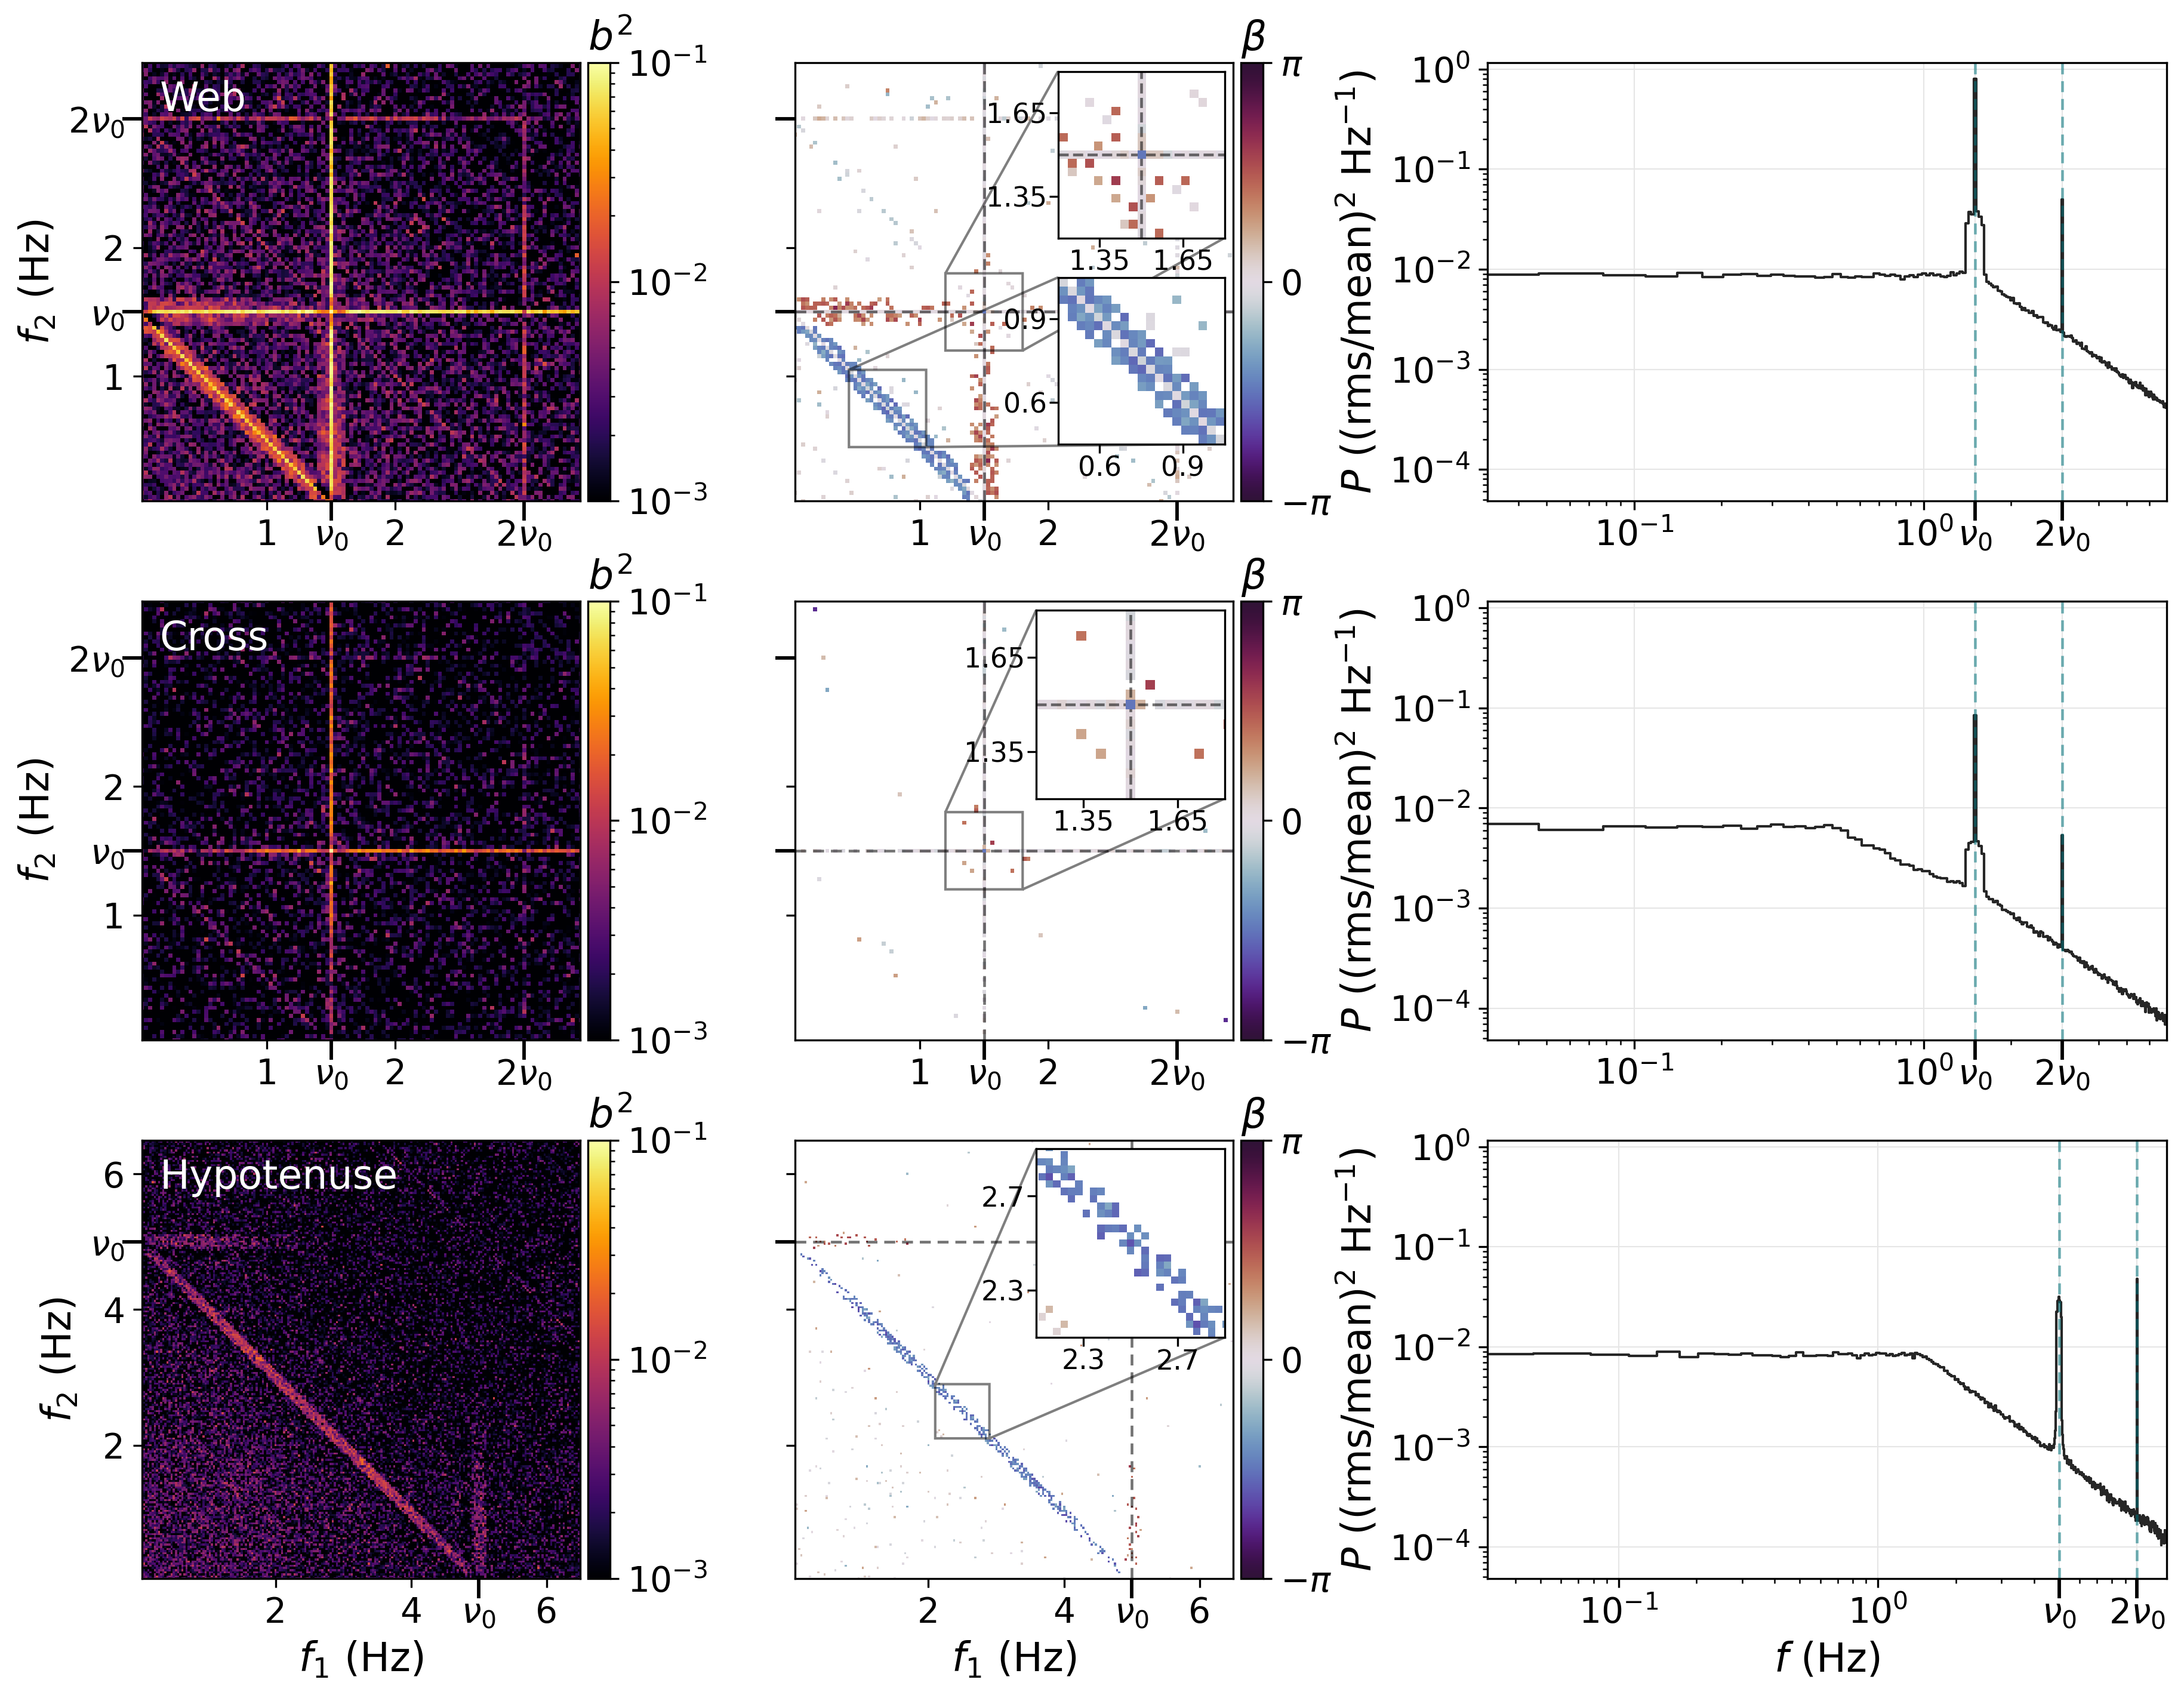

In [3]:

with plt.rc_context(paper_rc):
    fig, axes = plot_patterns(items, row_labels, height=9.3)
    # web: two insets down the right side, (nu0, nu0) above and the ridge centre below
    zoom_inset(axes[0, 1], items[0][1][4], 0.3, origin=(0.6, 0.6), size=0.38)
    zoom_inset(axes[0, 1], items[0][1][4] / 2, 0.3, origin=(0.6, 0.13), size=0.38)
    # insets: cross at the arm crossing (nu0, nu0); hypotenuse at the ridge centre (nu0/2, nu0/2)
    zoom_inset(axes[1, 1], items[1][1][4], 0.3)
    zoom_inset(axes[2, 1], items[2][1][4] / 2, 0.4)

    common_psd_ylim(axes)

    plt.savefig(f'{OUTROOT}/patterns_9panel.pdf', bbox_inches='tight', pad_inches=0.03)
    plt.show(fig)



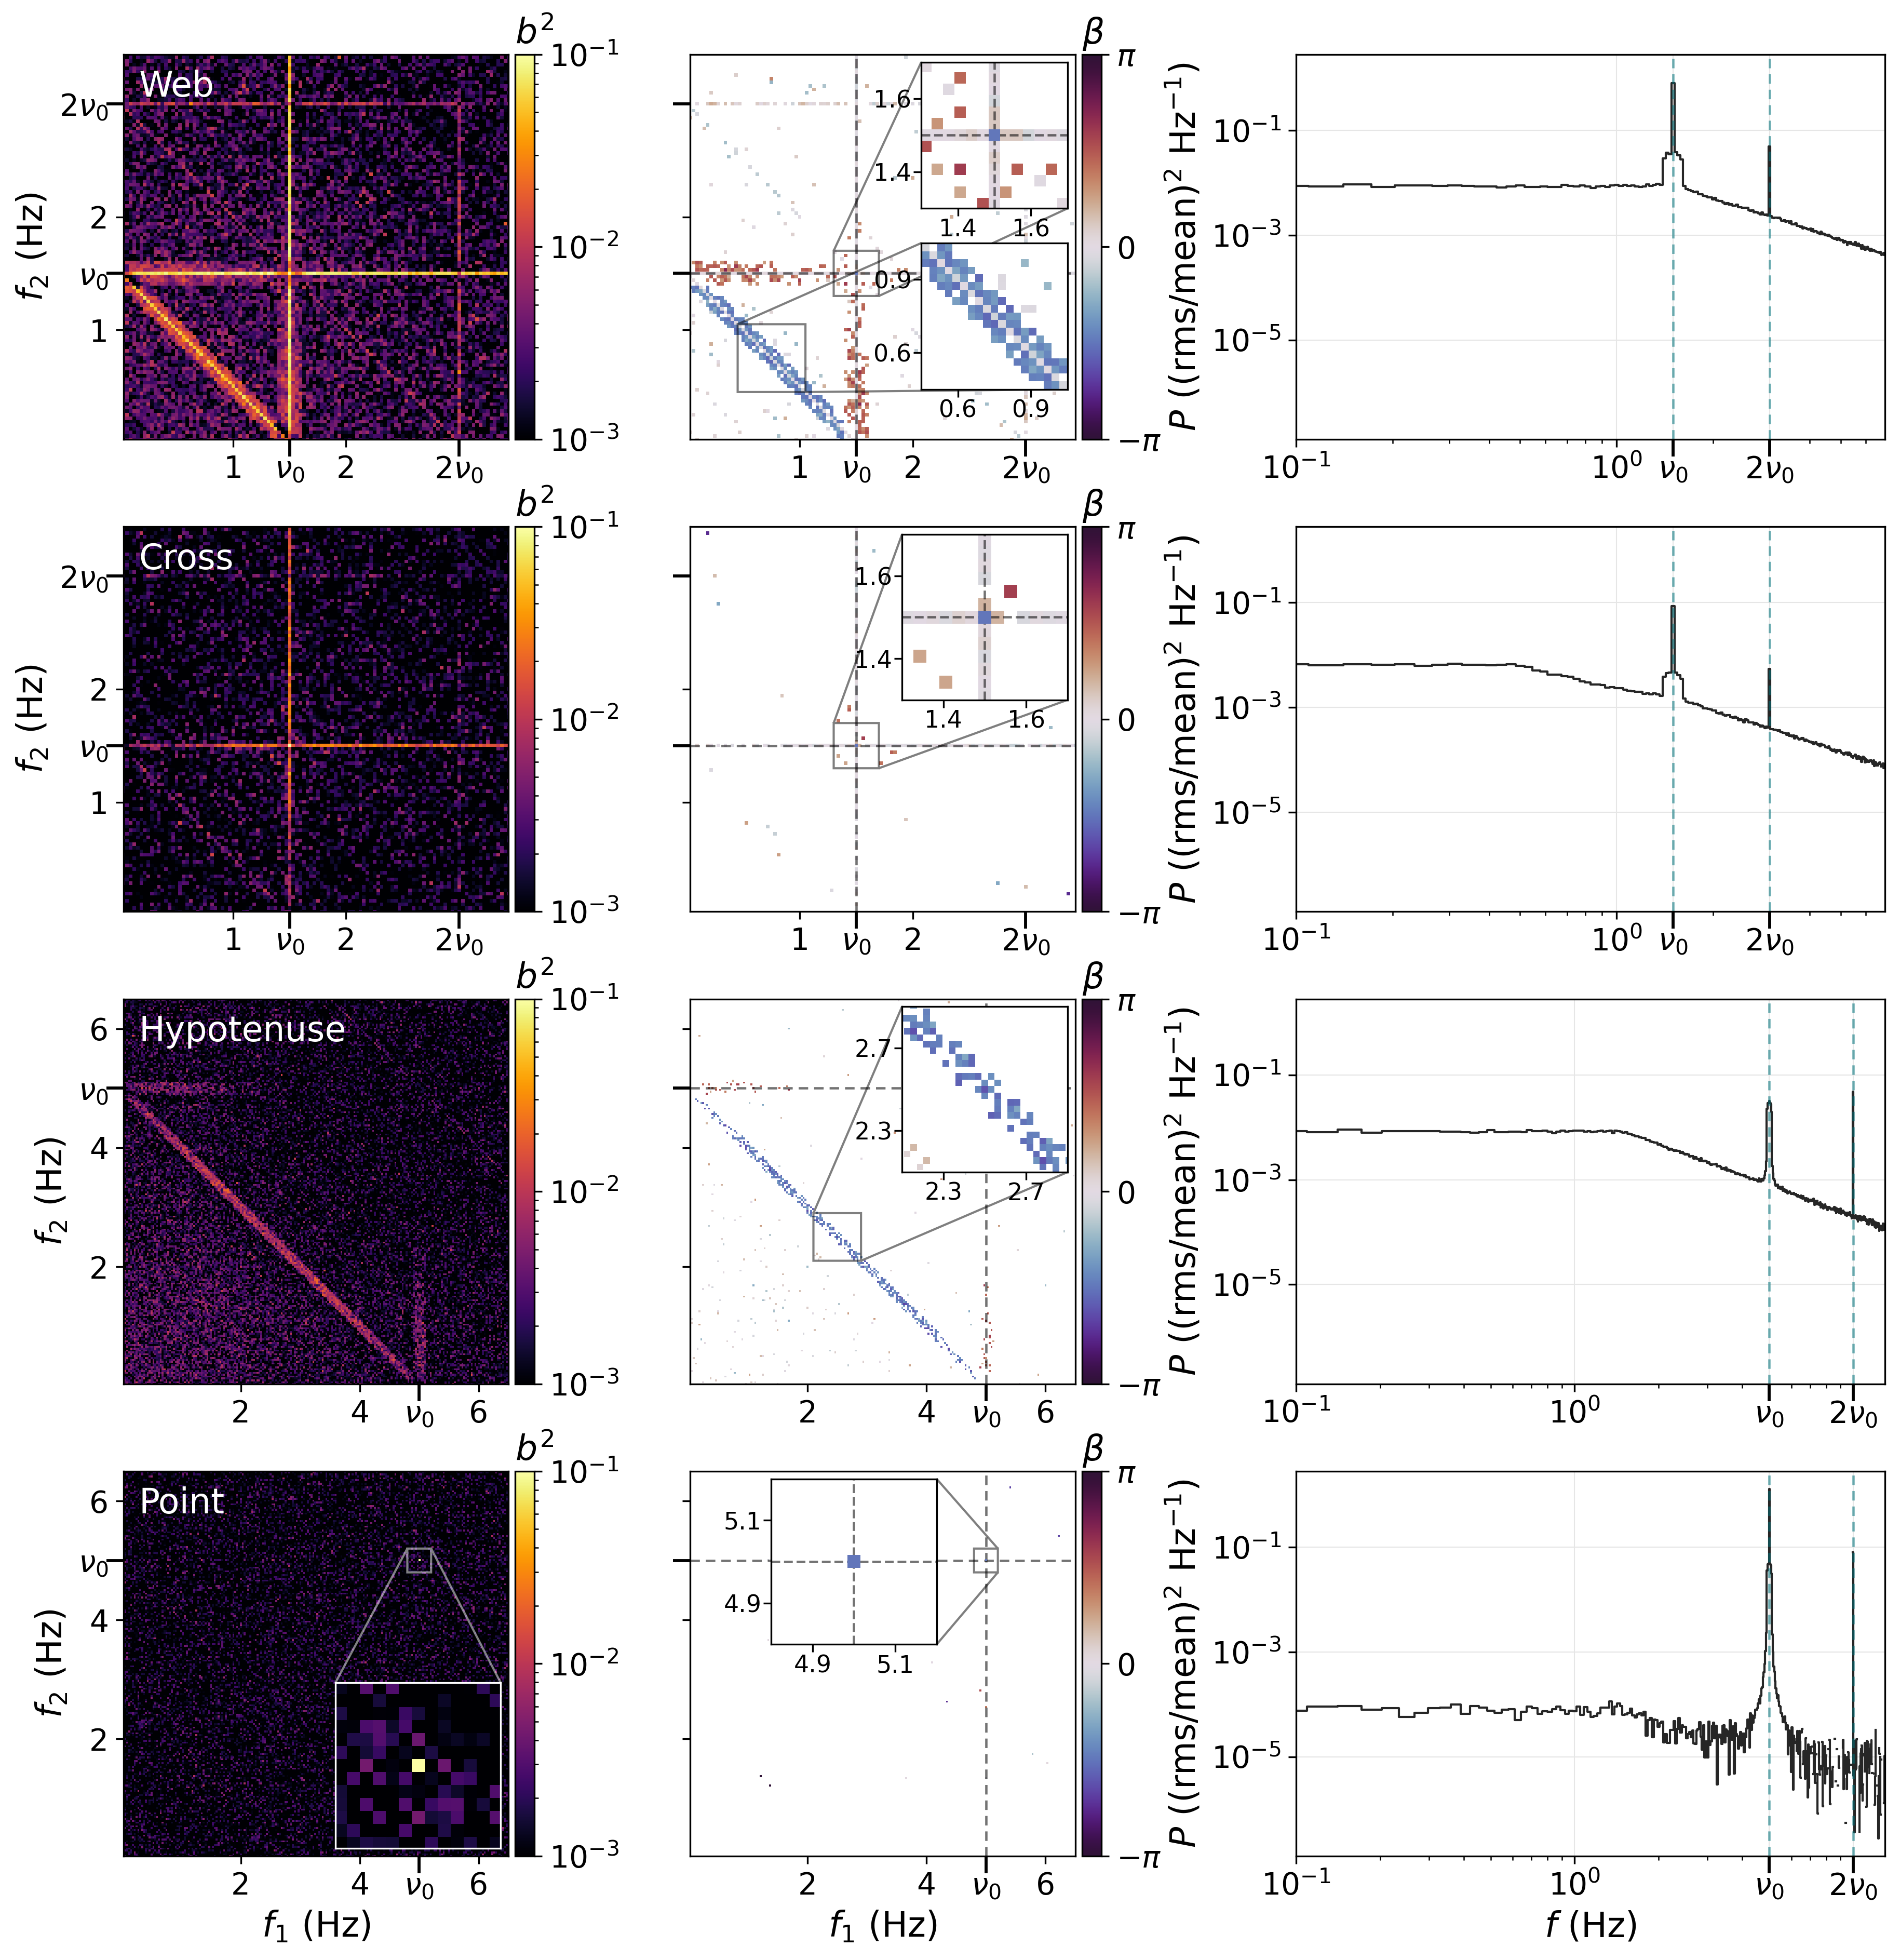

In [4]:
# FIGURE 1b: the three rows above plus the point state (uses the cell above)
# Point: type-B-like -- weak flow noise and dilution, QPO at 5 Hz; only (nu0, nu0) survives.

p_point = sm.replace(WEB, sig_g=.015, D=.005, nu0=5)
r_point, pdata = sm.metrics('point', p_point, shot_noise=True)
items_12 = items + [('point', pdata)]

with plt.rc_context(paper_rc):
    fig, axes = plot_patterns(items_12, row_labels + ['Point'], height=12.4)
    # web: two insets down the right side, (nu0, nu0) above and the ridge centre below
    zoom_inset(axes[0, 1], items_12[0][1][4], 0.2, origin=(0.6, 0.6), size=0.38)
    zoom_inset(axes[0, 1], items_12[0][1][4] / 2, 0.3, origin=(0.6, 0.13), size=0.38)
    # insets: cross and point at (nu0, nu0); hypotenuse at the ridge centre (nu0/2, nu0/2)
    zoom_inset(axes[1, 1], items_12[1][1][4], 0.2)
    zoom_inset(axes[2, 1], items_12[2][1][4] / 2, 0.4)
    # point: (nu0, nu0) sits in the upper right, so these insets move clear of it. The b2
    # inset (lower right, white frame on the dark map) shows the same window, unlabelled.
    zoom_inset(axes[3, 0], items_12[3][1][4], 0.2, origin=(0.55, 0.02), ticks=False, edgecolor='w')
    zoom_inset(axes[3, 1], items_12[3][1][4], 0.2, origin=(0.21, 0.55))  # room for y labels

    # truncate the left edge of the PSDs
    for ax in axes[:,-1]:
        ax.set_xlim((.1,None))

    common_psd_ylim(axes)

    plt.savefig(f'{OUTROOT}/patterns_12panel.pdf', bbox_inches='tight', pad_inches=0.03)
    plt.show(fig)



In [5]:
for run_name, params in runs + [('point', p_point)]:
    _,eta,Q = sm.controls(params,params.nu0/2,)
    
    print(f'{run_name}: eta: {eta}, Q: {Q}')

web: eta: [0.05267655], Q: [0.09557817]


cross: eta: [2.96261727], Q: [0.09557817]
hyp: eta: [0.11063438], Q: [25.41232764]


point: eta: [11.85203809], Q: [0.06353082]


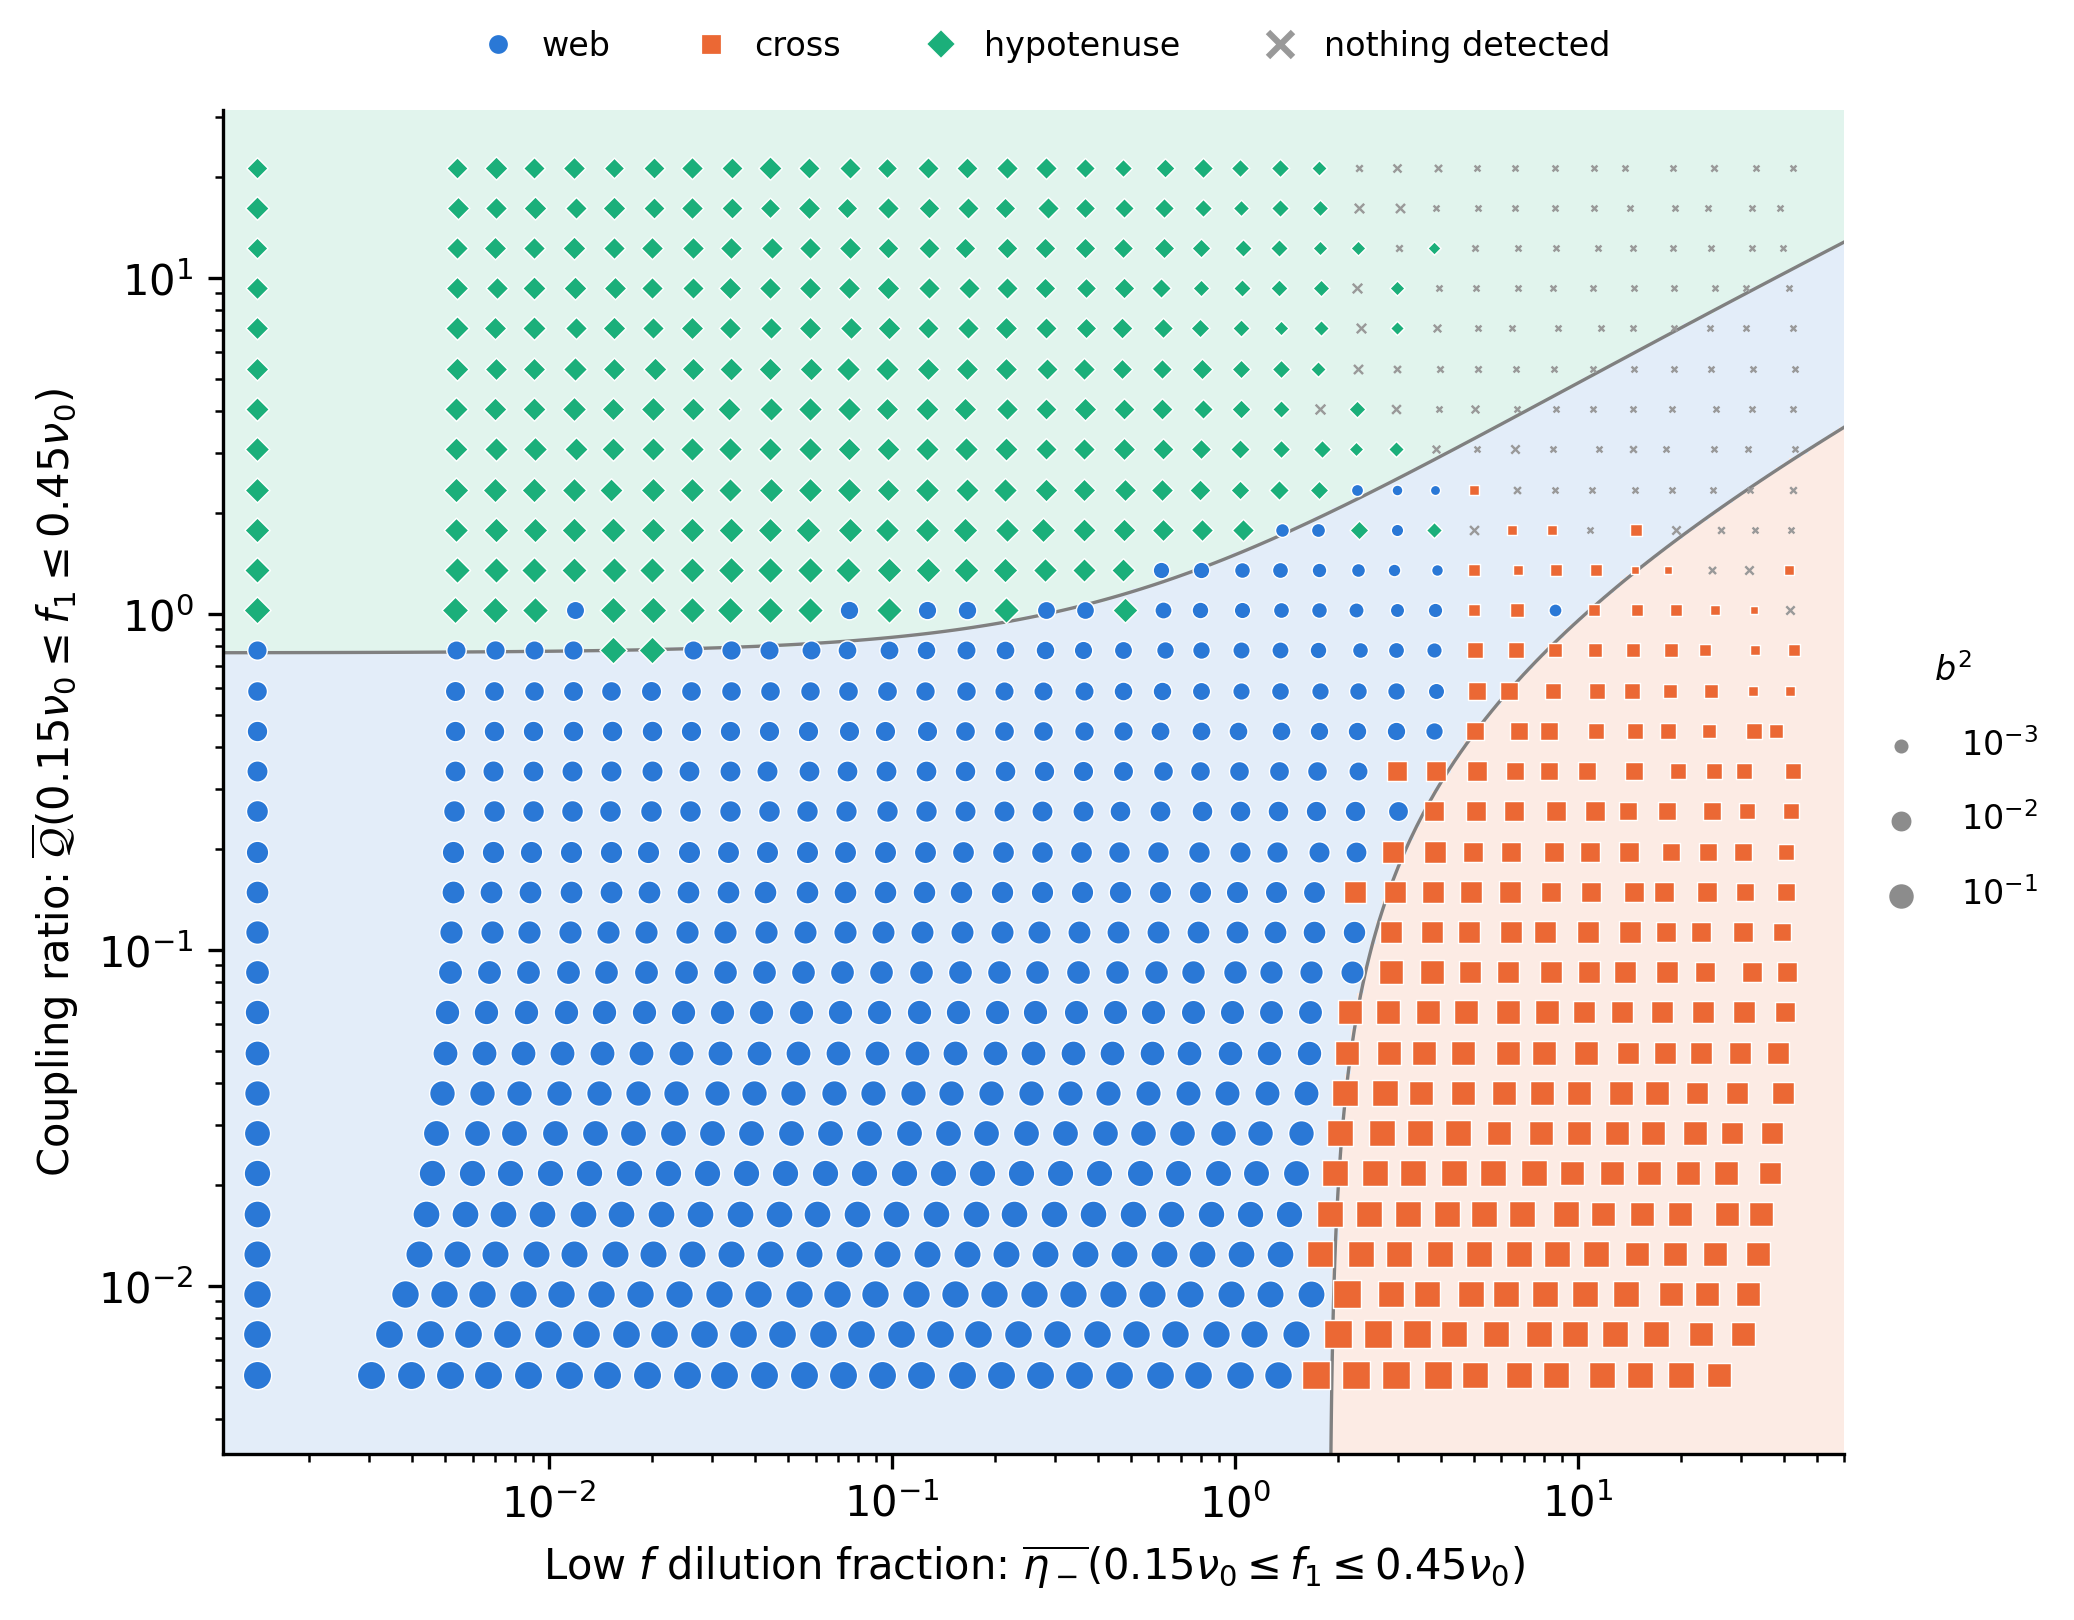

{'cross': 228, 'hyp': 280, 'none': 107, 'web': 501}


In [6]:
# Figure 4: pattern in the (d, Q) plane -- dilution contrast vs coupling ratio
# Grid: 31 a1 x 36 dilution rms, K=3000 (same as `python sim_dQ_grid.py --extra-dense`).
# Shading (same colours as the markers): pattern predicted by b2_hyp/b2_cross ~ W (1+Q)^2/(1+d);
# markers: measured pattern; area ~ log of the stronger locus' b2 (floor-subtracted).

import sim_dQ_grid as dq
dq = importlib.reload(dq)

# Load the saved grid, or regenerate it (1116 runs at K=3000, ~40 min) if it is missing.
# run_grid restores sm.K, so the settings of cell 0 survive.
dq_path = os.path.join(dq.OUT, 'sim_dQ_grid_extra_dense.json')
if os.path.exists(dq_path):
    with open(dq_path) as fh:
        dq_runs = json.load(fh)['runs']
else:
    dq_runs = dq.run_grid('extra_dense', path=dq_path)

fig, ax = plt.subplots(figsize=(6.8, 5.3), layout='constrained')  # keeps outside legends in frame
# marker areas / 4: the extra-dense grid halves the point spacing on both axes
dq_scale = 0.33
dq.plot_plane(ax, dq_runs, label_a1=(), region_labels=False, size_by_b2=True,
              size_scale=dq_scale)
fig.legend(handles=dq.legend_handles(ms=6), fontsize=8, frameon=False, ncol=4,
           loc='outside upper center', handletextpad=0.3)
# marker area ~ log of the stronger locus' floor-subtracted mean b2
ax.legend(handles=dq.size_handles(size_scale=dq_scale), title=r'$b^2$', fontsize=8, title_fontsize=8,
          frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5),
          labelspacing=1.2, borderpad=0.2)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

ax.set_xlabel(r'Low $f$ dilution fraction: $\overline{\eta_-}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
ax.set_ylabel(r'Coupling ratio: $\overline{\mathcal{Q}}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
ax.set_xlim((None,60))

plt.savefig(f'{OUTROOT}/eta_Q_grid.pdf')
plt.show(fig)

pprint({k: sum(r['pattern'] == k for r in dq_runs) for k in dq.PAT})


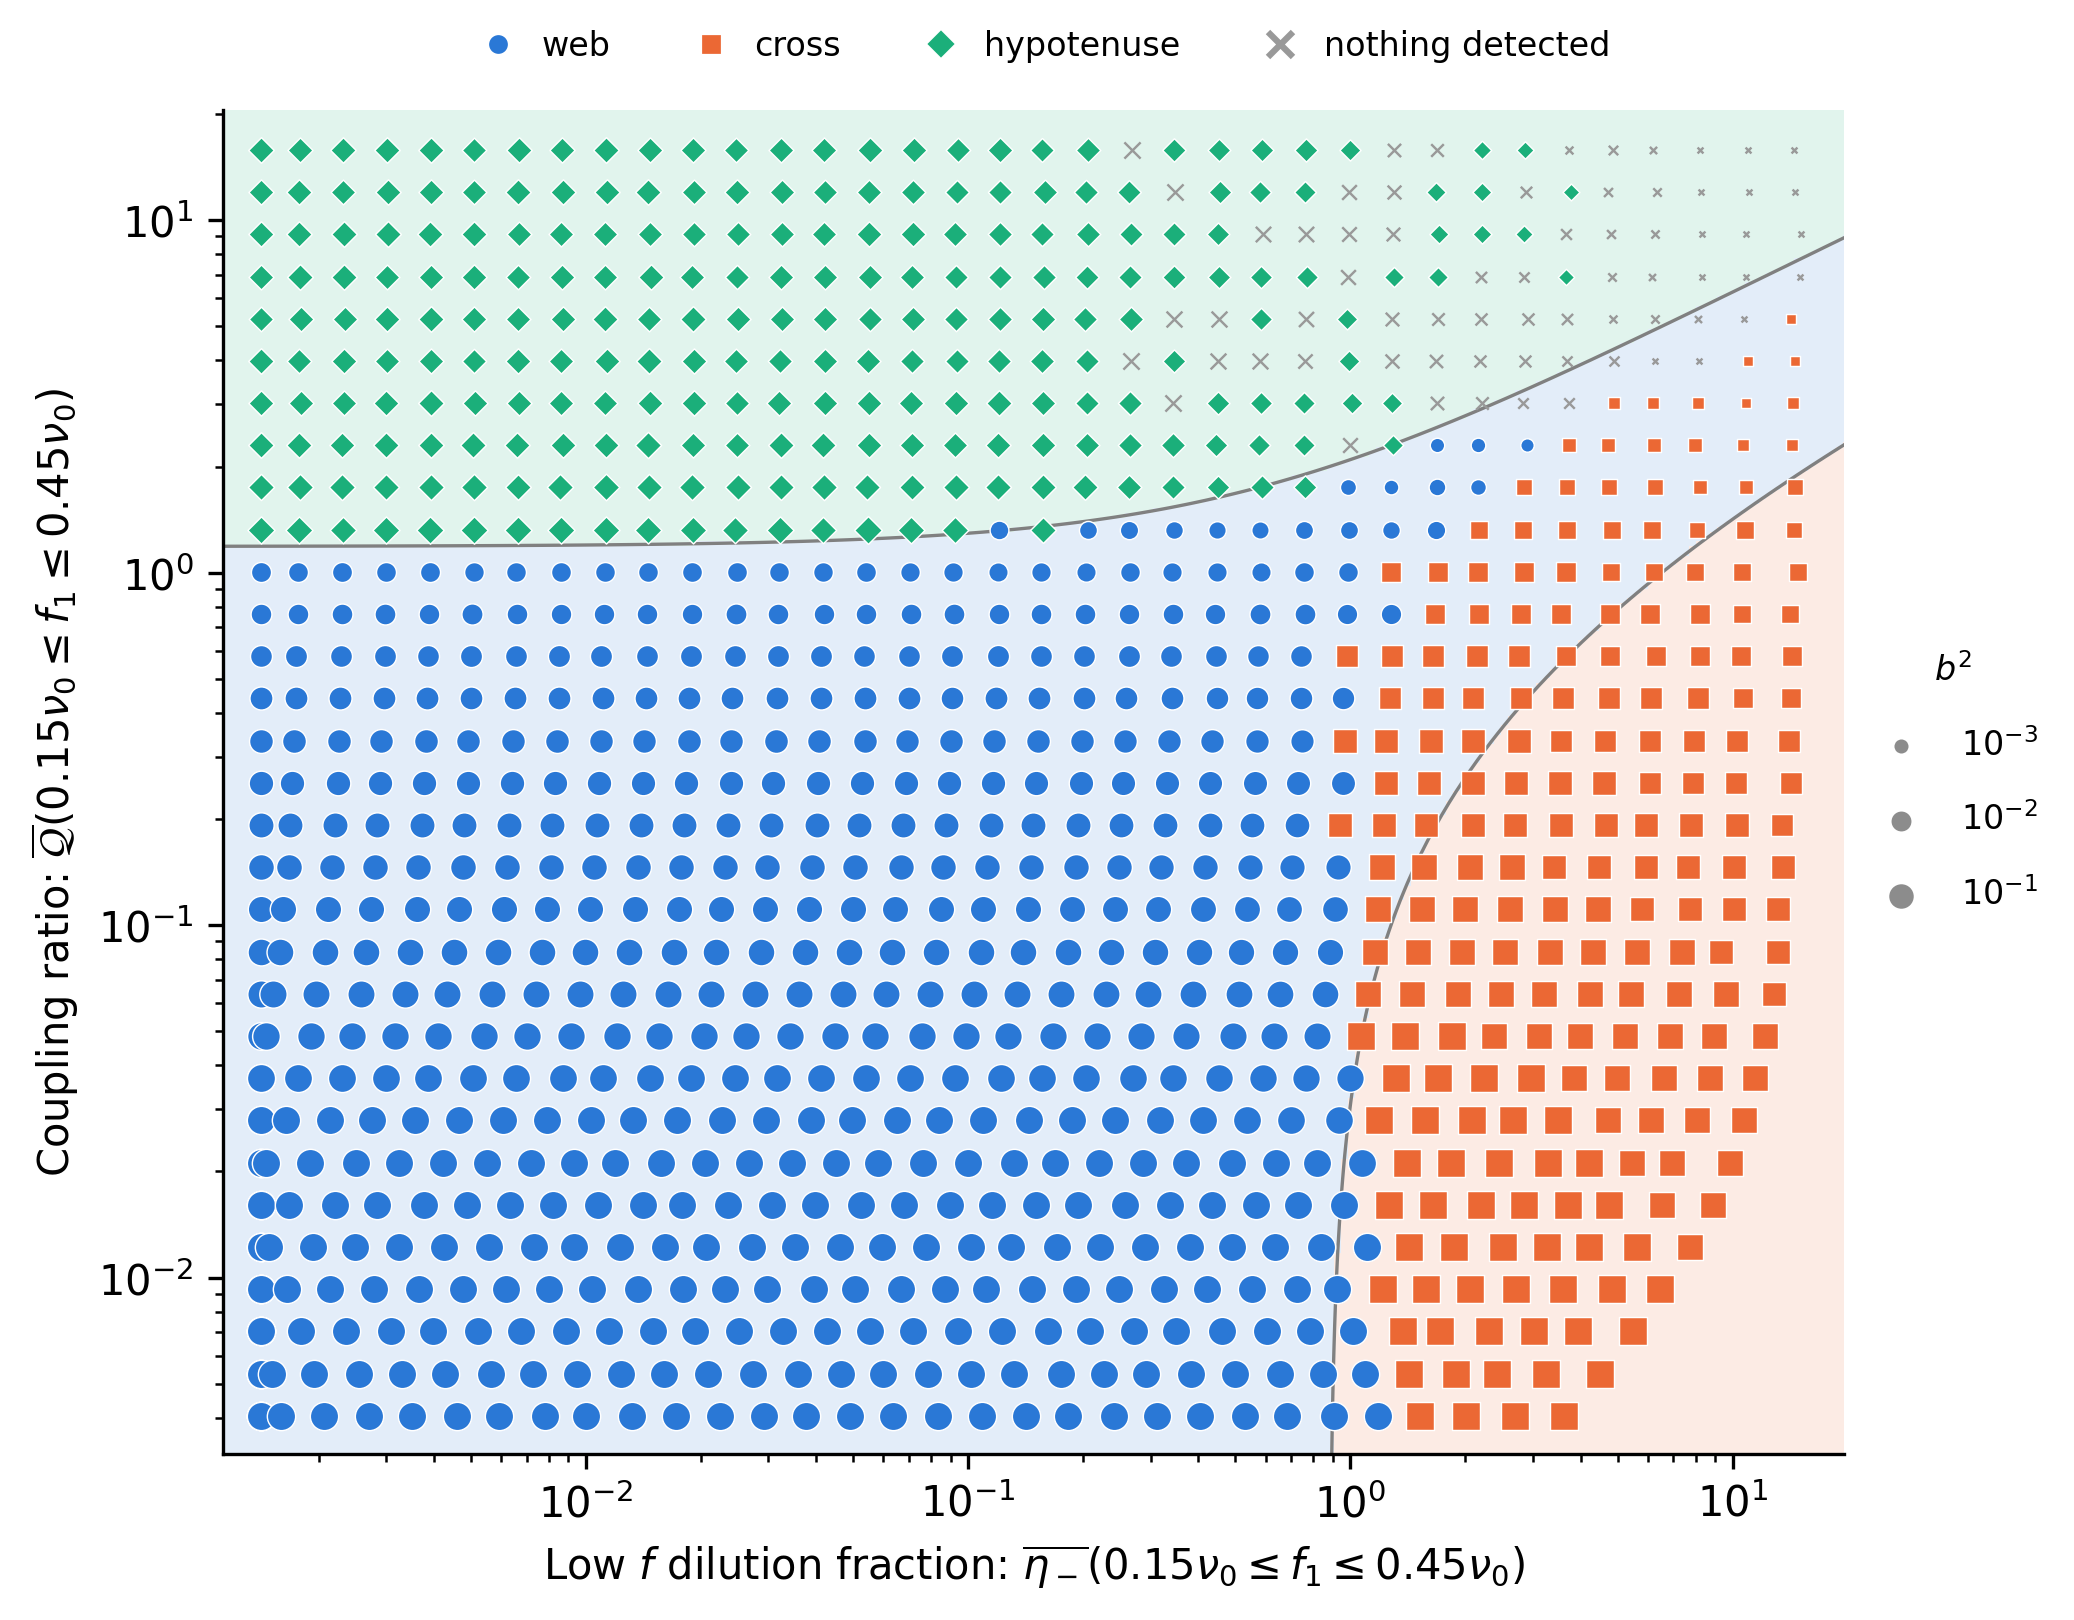

{'cross': 214, 'hyp': 248, 'none': 66, 'web': 588}


In [7]:
# Figure 4b: the same (eta, Q) plane on a WEB-matched base -- WEB with nu0 = 5, the flow
# slope of the Figure 4 base (pl_slope = 5) and the dilution cut off above nu0 (nd_fc = nu0).
# Those three are the settings the rule needs; every other parameter is WEB's.
# Dials: a1 and nd_rms (scaled by 1/D, so the dilution rms D * nd_rms matches Figure 4).

dq_web_base = sm.replace(WEB, nu0=5.0, pl_slope=5.0, nd_fc=5.0)

# Load the saved grid, or regenerate it (1116 runs, ~40 min on 11 workers) if it is missing
# or was run on a different base.
dq_web_path = os.path.join(dq.OUT, 'sim_dQ_grid_extra_dense_web.json')
dq_web = json.load(open(dq_web_path)) if os.path.exists(dq_web_path) else None
if dq_web is not None and dq_web['base'] == repr(dq_web_base):
    dq_web_runs = dq_web['runs']
else:
    dq_web_runs = dq.run_grid('extra_dense_web', path=dq_web_path, workers=11, base=dq_web_base)

fig, ax = plt.subplots(figsize=(6.8, 5.3), layout='constrained')  # keeps outside legends in frame
dq.plot_plane(ax, dq_web_runs, label_a1=(), region_labels=False, size_by_b2=True,
              size_scale=dq_scale)
fig.legend(handles=dq.legend_handles(ms=6), fontsize=8, frameon=False, ncol=4,
           loc='outside upper center', handletextpad=0.3)
# marker area ~ log of the stronger locus' floor-subtracted mean b2
ax.legend(handles=dq.size_handles(size_scale=dq_scale), title=r'$b^2$', fontsize=8, title_fontsize=8,
          frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5),
          labelspacing=1.2, borderpad=0.2)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

ax.set_xlabel(r'Low $f$ dilution fraction: $\overline{\eta_-}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
ax.set_ylabel(r'Coupling ratio: $\overline{\mathcal{Q}}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
ax.set_xlim((None, 1.3 * max(r['d'] for r in dq_web_runs)))  # just past the last column
ax.set_ylim((None,1.3 * max(r['Q'] for r in dq_web_runs)))

plt.savefig(f'{OUTROOT}/eta_Q_grid_web.pdf')
plt.show(fig)

pprint({k: sum(r['pattern'] == k for r in dq_web_runs) for k in dq.PAT})
